# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [136]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True

import warnings
warnings.filterwarnings("ignore", category=UserWarning)


In [137]:
psi0 = np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T

## 2. Run DB-QITE with DME

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


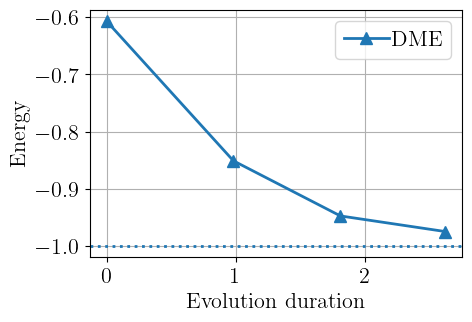

In [138]:
RGCI_dme = GCI(QITE_dme_select_M(), psi0, None, [0.99,0.91,0.9])
results_RGCI_dme = RGCI_dme.execute_gci()
RGCI_dme.plot_GCI_results(results_RGCI_dme)

In [139]:
# Step size ptimization
from scipy.optimize import minimize
def max_excitation(thetas, fidelity, target_fidelity, tolerance=1e-2):
    """
    Find the x value corresponding to y = y_const within a given tolerance.
    """
    return next((xi for xi, yi in zip(thetas, fidelity) if abs(yi - target_fidelity) <= tolerance), None)

### 2.1 k=1

In [140]:
optimal_s_for_M_k1 = []
Ms = [1,2,50]
k = 1
for M in Ms:
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        return GCI(QITE_dme_select_M(M), psi0, None, [s]).execute_gci()[0][-1].real

    init_guess = 0.6
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k1.append((M,[optimal_s]))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k1)

Optimal s for M = 1, k = 1: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 1: s = 0.88, phi = 0.94
t = 0.0745 tau
Optimal s for M = 50, k = 1: s = 0.95, phi = 0.98
t = 0.0031 tau
[(1, [0.785398159105983]), (2, [0.8757927102818437]), (50, [0.952138829593977])]


In [141]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)

res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k1:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, s).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [142]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.68)
(2, 0.62)
(50, 0.52)


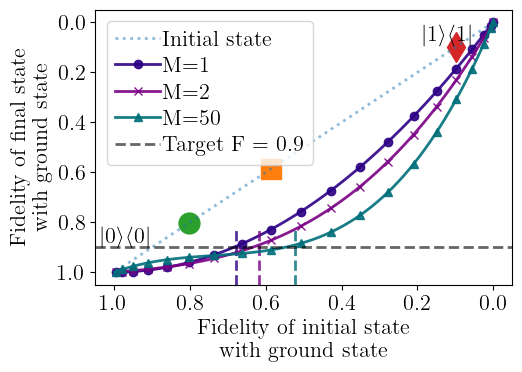

In [143]:
state_0 = np.array([1, 0], dtype=complex)
def fidelity_with_0(state):
    shape = np.shape(state)
    if shape[0] == shape[1]:
        return np.real(np.conj(state_0).T @ state @ state_0)
    else:
        dm = state@state.T.conj()
        return np.real(np.conj(state_0).T @ dm @ state_0)
    
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
# color = cm.rainbow(np.linspace(1, 0, len(Ms)))
color = ['#2c0084','#7a0085','#006f7a','C0']

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
# ax.plot(np.linspace(0,1,number_steps),res_ITE,label=r"$ITE |{\Psi(\tau)}\rangle$",marker="^")
# ax.plot(np.linspace(0,1,number_steps),res_DBI,label=r"$DBI |{\sigma_k}\rangle$",marker='o')
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state", alpha=0.5,linestyle=':')
plt.plot(fidelities_original[70],fidelity[70],color='C2', marker='o',markersize=15,zorder=0)
plt.plot(fidelities_original[55],fidelity[55],color='C1', marker='s',markersize=15,zorder=0)
plt.plot(fidelities_original[20],fidelity[20],color='C3', marker='d',markersize=15,zorder=0)
i=0

markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    # if i==0:
    #     plt.plot(fidelities_original[70],np.real(value)[70],color='C2', marker='o',markersize=15,zorder=-1)
    i+=1

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}',linestyle='--')
# ax.legend(bbox_to_anchor=(1.05, 1))
ax.legend()
##ax.grid()

plt.text(fidelities_original[0]+0.05, fidelity[0] + 0.1, r'$|1\rangle\langle 1|$', ha='right', va='bottom')
plt.text(fidelities_original[-1]-0.1, fidelity[-1] - 0.18, r'$|0\rangle\langle 0|$', ha='right',va='top')
plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))



### 2.2 k=2

In [144]:
# psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
# psis = []
# number_steps = 50
# for i in np.linspace(0,1,number_steps):
#     psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
# psis = np.asarray(psis)

# times_ITE = np.linspace(0.04,0.7,100).tolist()
# res_ITE = []
# res_DBI = []
# res_init = []
# dict_res_RHOPF = {}

# num_s = 15
# for s in np.linspace(0.01,1,num_s):
#     res_RGCI = []
#     for psi0 in psis:
#         res_RGCI.append(GCI(QITE_dme_select_M(M=2), psi0, None, [s]).execute_gci()[0][-1])
#         dict_res_RHOPF.update({r"$|{\omega_k}\rangle$" +f' for s={np.round(s,2)}' : res_RGCI})

In [145]:
# from matplotlib import cm
# rainbow_color = cm.rainbow(np.linspace(1, 0, num_s))
# plt.figure(figsize=(10,5))
# i=0
# for key,value in dict_res_RHOPF.items():
#     plt.plot(np.linspace(0,1,number_steps),value,label=key,marker='x',color=rainbow_color[i],alpha=0.5)
#     i+=1
# plt.ylabel('Energy')
# plt.xlabel(r'$n$, initial state is $e^{i n\pi/2 \sigma_X} |+i\rangle (\sigma_Y$ eigenstate)')
# plt.legend(bbox_to_anchor=(1.05, 1))
# # plt.grid()

In [146]:
optimal_s_for_M_k2 = []
# s_list = []
k = 2
for i, M in enumerate(Ms):
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        
        return GCI(QITE_dme_select_M(M), psi0, None, optimal_s_for_M_k1[i][1] +[s]).execute_gci()[0][-1].real
    # print(optimal_s_for_M_k1[i][1])

    init_guess = 0.71
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k2.append((M,optimal_s_for_M_k1[i][1] + [optimal_s]))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k2)

Optimal s for M = 1, k = 2: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 2: s = 0.8, phi = 0.89
t = 0.071 tau
Optimal s for M = 50, k = 2: s = 0.74, phi = 0.86
t = 0.0027 tau
[(1, [0.785398159105983, 0.7853986722291612]), (2, [0.8757927102818437, 0.7953183070496507]), (50, [0.952138829593977, 0.7417080168515039])]


In [147]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)


res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k2:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, s).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [148]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.54)
(2, 0.51)
(50, 0.24)


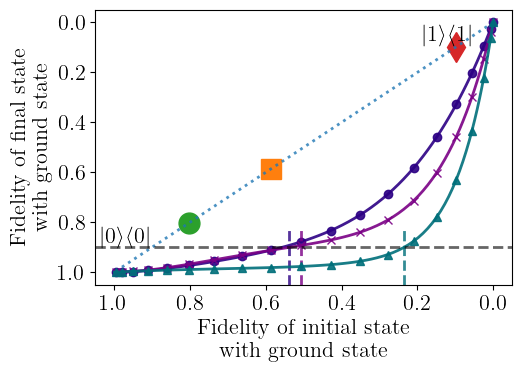

In [149]:
fidelities_original = [fidelity_with_0(x) for x in psis]

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state",linestyle=':', alpha=0.8)

plt.plot(fidelities_original[70],fidelity[70],color='C2', marker='o',markersize=15,zorder=0)
plt.plot(fidelities_original[55],fidelity[55],color='C1', marker='s',markersize=15,zorder=0)
plt.plot(fidelities_original[20],fidelity[20],color='C3', marker='d',markersize=15,zorder=0)

i=0
markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    # if i==0:
    #     plt.plot(fidelities_original[55],np.real(value)[55],color='C1', marker='s',markersize=15,zorder=0)
    # if i==1:
    #     plt.plot(fidelities_original[20],np.real(value)[20],color='C3', marker='d',markersize=15,zorder=0)
    i+=1


plt.gca().invert_xaxis()
plt.gca().invert_yaxis()


# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}',linestyle='--')
# ax.legend(bbox_to_anchor=(1.05, 1))

#ax.grid()
plt.text(fidelities_original[0]+0.05, fidelity[0] + 0.1, r'$|1\rangle\langle 1|$', ha='right', va='bottom')
plt.text(fidelities_original[-1]-0.1, fidelity[-1] - 0.18, r'$|0\rangle\langle 0|$', ha='right',va='top')
plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))

### 2.3 k=3

In [150]:
optimal_s_for_M_k3 = []
k = 3
for i, M in enumerate(Ms):
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        return GCI(QITE_dme_select_M(M), psi0, None, optimal_s_for_M_k2[i][1] + [s]).execute_gci()[0][-1].real

    init_guess = 0.8
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k3.append((M,optimal_s_for_M_k2[i][1] + [optimal_s]))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k3)

Optimal s for M = 1, k = 3: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 3: s = 0.79, phi = 0.89
t = 0.0707 tau
Optimal s for M = 50, k = 3: s = 0.71, phi = 0.84
t = 0.0027 tau
[(1, [0.785398159105983, 0.7853986722291612, 0.7853951538529089]), (2, [0.8757927102818437, 0.7953183070496507, 0.7904218544089816]), (50, [0.952138829593977, 0.7417080168515039, 0.710371894811362])]


In [151]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)


res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k3:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, s).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [152]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.66)
(2, 0.69)
(50, 0.1)


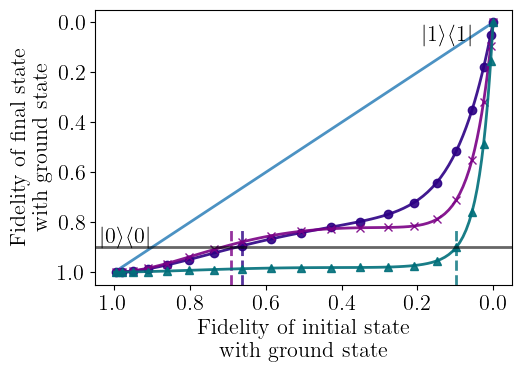

In [153]:
fidelities_original = [fidelity_with_0(x) for x in psis]

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state", alpha=0.8)
i=0

markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)

    i+=1
    

ax.plot

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}')
# ax.legend(bbox_to_anchor=(1.05, 1))
if k==1:
        ax.legend()
#ax.grid()

plt.text(fidelities_original[0]+0.05, fidelity[0] + 0.1, r'$|1\rangle\langle 1|$', ha='right', va='bottom')
plt.text(fidelities_original[-1]-0.1, fidelity[-1] - 0.18, r'$|0\rangle\langle 0|$', ha='right',va='top')

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))



In [154]:
# from qutip import Bloch, Qobj
# import qutip
# b = Bloch()
# from matplotlib import cm
# color = cm.rainbow(np.linspace(1, 0, len(states)))
# b.vector_color = color.tolist()

# for state in states:
#     rho = Qobj(state)
#     b.add_states(rho)

# # Fidelity target and corresponding theta
# fidelity = 0.9
# theta = 2 * np.arccos(np.sqrt(fidelity))

# # Generate points for various phi values
# phi_values = np.linspace(0, 2 * np.pi, 50)  # 100 points around the circle
# bloch_vectors = [
#     [np.sin(theta) * np.cos(phi),  # x-coordinate
#      np.sin(theta) * np.sin(phi),  # y-coordinate
#      np.cos(theta)]                # z-coordinate
#     for phi in phi_values
# ]

# # Initialize Bloch sphere
# # b = Bloch()
# b.point_color = ['k']
# b.point_marker = ['.']


# # Add points to the Bloch sphere
# for vec in bloch_vectors:
#     b.add_points(vec)

# b.show()

In [155]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

def density_matrix_to_bloch(state):
    """
    Convert a 2x2 density matrix to Bloch vector coordinates (u, v, w).
    
    Parameters:
    density_matrix (ndarray): A 2x2 density matrix.
    
    Returns:
    tuple: The Bloch vector components (u, v, w).
    """
    if np.shape(state)[0] != np.shape(state)[1]:
        density_matrix = np.outer(state, np.conj(state))
    elif np.shape(state)[0] == np.shape(state)[1]:
        density_matrix = state

    # Extract matrix elements
    rho_00 = density_matrix[0, 0]
    rho_01 = density_matrix[0, 1]
    rho_10 = density_matrix[1, 0]
    rho_11 = density_matrix[1, 1]
    
    # Calculate the components of the Bloch vector
    u = 2 * np.real(rho_01)
    v = 2 * np.imag(rho_10)
    w = rho_00 - rho_11
    
    return u, v, w


In [156]:


# Function to plot the Bloch vector on the Bloch sphere
def plot_bloch_sphere(font_size=20):
    """
    Plots the Bloch sphere with the surface, latitude and longitude lines, and the |0⟩ and |1⟩ labels at the poles.
    
    Parameters:
    ax (matplotlib.axes._axes.Axes): The axes on which to plot the Bloch sphere.
    font_size (int): Font size for labels.
    """
    # Create a meshgrid for the sphere surface
    u = np.linspace(0, 2 * np.pi, 100)
    v = np.linspace(0, np.pi, 100)
    u, v = np.meshgrid(u, v)

    # Parametric equations for the sphere surface
    x_sphere = np.sin(v) * np.cos(u)
    y_sphere = np.sin(v) * np.sin(u)
    z_sphere = np.cos(v)
    
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(x_sphere, y_sphere, z_sphere, color='b',alpha=0.03)
    
    # Plot the longitude lines (azimuthal angles)
    for i in range(0, 360, 90):  # Longitude lines at every 90 degrees
        phi = np.radians(i)
        x_longitude = np.sin(v) * np.cos(phi)
        y_longitude = np.sin(v) * np.sin(phi)
        z_longitude = np.cos(v)
        ax.plot(x_longitude, y_longitude, z_longitude, color='k', lw=0.4, alpha=0.2)
    
    # Plot the latitude lines (polar angles)
    # for i in range(0, 180, 90):  # Latitude lines at every 90 degrees
    theta = np.radians(90)
    x_latitude = np.outer(np.cos(u), np.sin(theta))
    y_latitude = np.outer(np.sin(u), np.sin(theta))
    z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
    ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=0.1, alpha=0.01)

    # Add the |0⟩ label at the north pole
    ax.text(0, 0, 1.2, r'$|0\rangle$', fontsize=font_size, color='k', ha='center', va='center')

    # Add the |1⟩ label at the south pole
    ax.text(0, 0, -1.1, r'$|1\rangle$', fontsize=font_size, color='k', ha='center', va='center')

    # Plot the x, y, z axes as black thick lines
    ax.plot([0, 1], [0, 0], [0, 0], color='k', lw=1)  # X axis
    ax.plot([0, 0], [0, 1], [0, 0], color='k', lw=1)  # Y axis
    ax.plot([0, 0], [0, 0], [0, 1], color='k', lw=1)  # Z axis

    # Add labels at the end of each axis
    ax.text(1.1, 0, 0, r'$x$', fontsize=font_size, color='k', ha='center', va='center')
    ax.text(0, 1.1, 0, r'$y$', fontsize=font_size, color='k', ha='center', va='center')
    ax.text(0, 0, 1.1, r'$z$', fontsize=font_size, color='k', ha='center', va='center')

    # Set the view angle and axis limits
    # ax.set_title("Bloch Sphere Representation", fontsize=font_size)
    ax.view_init(30, 30)  # Adjust view angle to look like a globe
    max_range = 1  # Since the Bloch sphere is a unit sphere
    ax.set_xlim([-max_range, max_range])
    ax.set_ylim([-max_range, max_range])
    ax.set_zlim([-max_range, max_range])
    ax.set_box_aspect([1, 1, 1])  # Equal scaling in all axes
    ax.set_axis_off()  # Hide the axes
    ax.grid(False)  # Remove the grid
    ax.set_facecolor('none')  # Remove the box/frame
    plt.tight_layout()

    return ax


In [157]:
import numpy as np
import matplotlib.pyplot as plt

def plot_bloch_vector(state, ax, color='r', num_points=100, text=None, marker=None, marker_color='k'):
    """
    Plots the Bloch vector as a red arrow on the Bloch sphere along with a latitude circle, 
    and optionally adds a text label to the latitude circle.

    Parameters:
    state (ndarray): The density matrix or state vector (2x2) for the system.
    ax (matplotlib.axes._axes.Axes): The axes on which to plot the vector.
    color (str): The color of the Bloch vector and latitude circle.
    num_points (int): Number of points to plot for the latitude circle.
    text (str or None): Text to place on the latitude circle (default is None).
    """
    # Get the Bloch vector components (x, y, z) from the density matrix or statevector
    x, y, z = density_matrix_to_bloch(state)  # Replace with your actual state data
    print(x, y, z)

    # Plot the Bloch vector (the red arrow)
    ax.quiver(0, 0, 0, x, y, z, color=color, length=1.0, arrow_length_ratio=0.1)

    if marker != None:
        # Plot a marker at the tip of the Bloch vector (x, y, z)
        ax.plot(x, y, z, color=marker_color, marker=marker,markersize=15)  # s is the size of the marker


    # Latitude circle components
    theta = np.arccos(np.real(z))
    u = np.linspace(0, 2 * np.pi, num_points)
    x_latitude = np.outer(np.cos(u), np.sin(theta))
    y_latitude = np.outer(np.sin(u), np.sin(theta))
    z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
    ax.plot(x_latitude, y_latitude, z_latitude, color=color, lw=0.7, alpha=0.5)

    # Add text to the latitude circle if provided
    if text:
        # Example: Placing text at a specific angle on the latitude circle (at angle=pi/4)
        angle = 0.15  # You can adjust this angle as needed
        x_text = np.sin(theta) * np.cos(angle)
        y_text = np.sin(theta) * np.sin(angle)
        z_text = np.cos(theta)
        ax.text(x_text, y_text, z_text, text, color=color, fontsize=20, ha='center', va='bottom')

    return ax



In [158]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def add_3d_outline(ax, x, y, z, color='black', linewidth=2):
    """
    Adds a silhouette outline to a 3D surface by detecting edge points.

    Parameters:
    ax : Matplotlib 3D axis
    x, y, z : 2D arrays defining the surface
    color : str, outline color
    linewidth : int, thickness of the outline

    Returns:
    ax : Updated 3D axis with the outline
    """

    # Compute surface normals using cross product
    dx, dy = np.gradient(x), np.gradient(y)
    dz = np.gradient(z)
    normals = np.cross(np.c_[dx[1], dy[1], dz[1]], np.c_[dx[0], dy[0], dz[0]])

    # Normalize normals
    normals /= np.linalg.norm(normals, axis=1)[:, np.newaxis]

    # Viewing direction (assume camera at (0,0,10), looking at origin)
    view_dir = np.array([0, 0, 10]) - np.array([0, 0, 0])
    view_dir /= np.linalg.norm(view_dir)

    # Compute dot product: If close to zero, it's an edge
    dot_product = np.abs(np.dot(normals, view_dir))
    edge_mask = dot_product < 0.2  # Threshold for edge detection

    # Extract silhouette points
    edge_x, edge_y, edge_z = x[edge_mask], y[edge_mask], z[edge_mask]

    # Plot the detected silhouette
    ax.plot(edge_x, edge_y, edge_z, color=color, linewidth=linewidth)
    
    return ax


In [159]:
color = ['C0','#2c0084','#7a0085','#006f7a']

In [160]:
states_good = GCI(QITE_dme_select_M(1), psis[70], None, optimal_s_for_M_k1[0][1]).execute_gci()[-3]
states_mid = GCI(QITE_dme_select_M(1), psis[55], None, optimal_s_for_M_k2[0][1]).execute_gci()[-3]
states_bad = GCI(QITE_dme_select_M(2), psis[30], None, optimal_s_for_M_k2[1][1]).execute_gci()[-3]

texts = ['Initial state',r'$k=1$',r'$k=2$']

0.0 0.7957618405308319 (0.605609687137667+0j)
-0.15692037927859365 0.15692038745539902 (0.9222281405601755-5.612726838120619e-18j)


c:\Python\Lib\site-packages\mpl_toolkits\mplot3d\axes3d.py:3305: ComplexWarning: Casting complex values to real discards the imaginary part
  UVW = np.column_stack(input_args[3:]).astype(float)


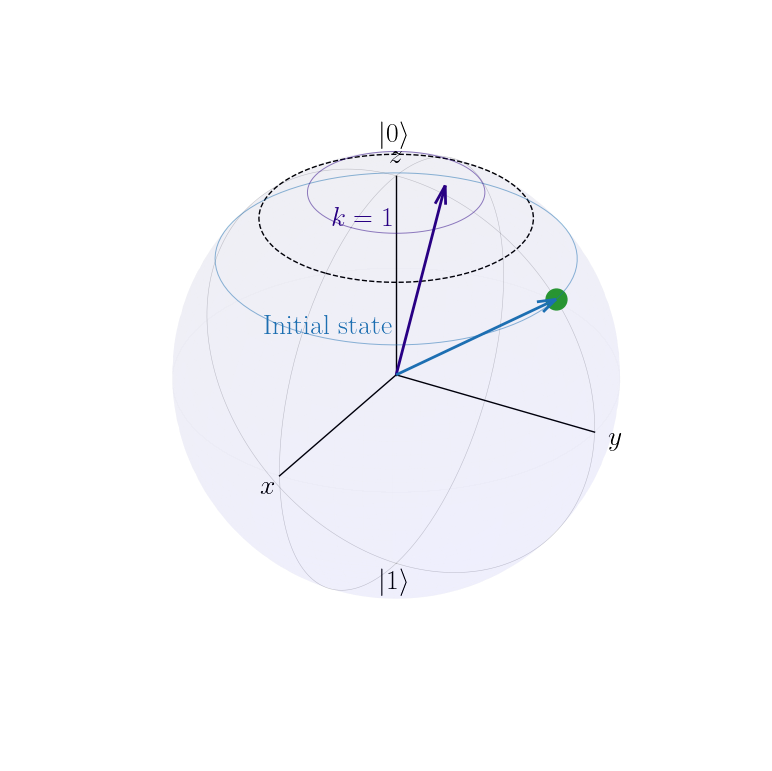

In [ ]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')

# Plot the Bloch sphere with vector
i=0
for state in states_good:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='o',marker_color='C2')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_good.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()

0.0 0.9848077530122081 (0.1736481776669303+0j)
-0.40689883718230235 0.4068988491272234 (0.6585713328634074-9.677436786386842e-18j)
-0.1389265862820082 -4.82737369994559e-07 (0.8241380014239202-7.423746654719317e-18j)


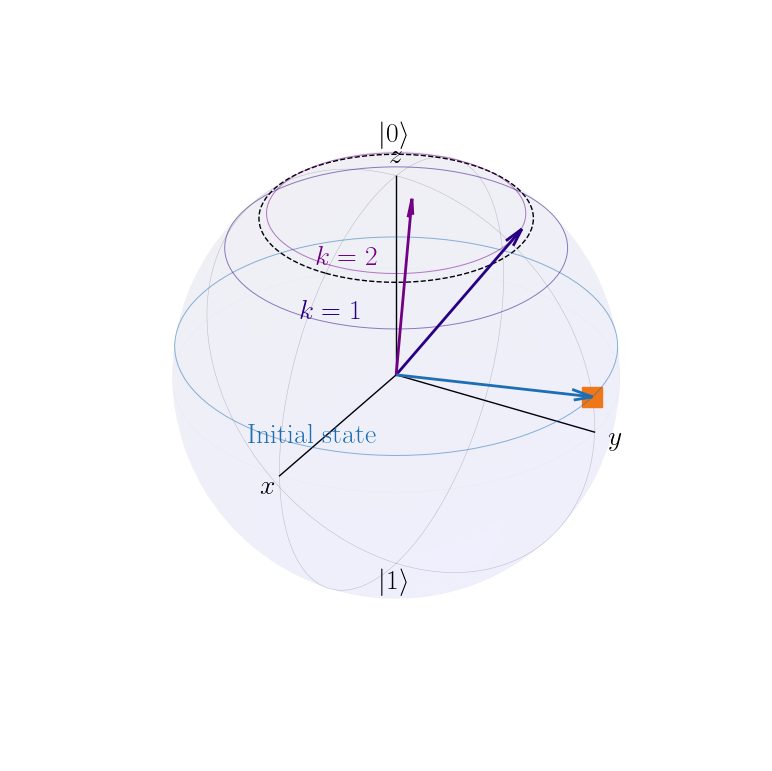

In [162]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')


# Plot the Bloch sphere with vector
i=0
for state in states_mid:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='s',marker_color='C1')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_mid.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()


0.0 0.8145759520503356 (-0.5800569095711983+0j)
-0.6390847655871552 0.668025005080452 (-0.10190766243710636-1.9902976434698883e-17j)
-0.6541997494738201 0.22959857701416975 (0.42810365453889476-9.291148581086727e-18j)


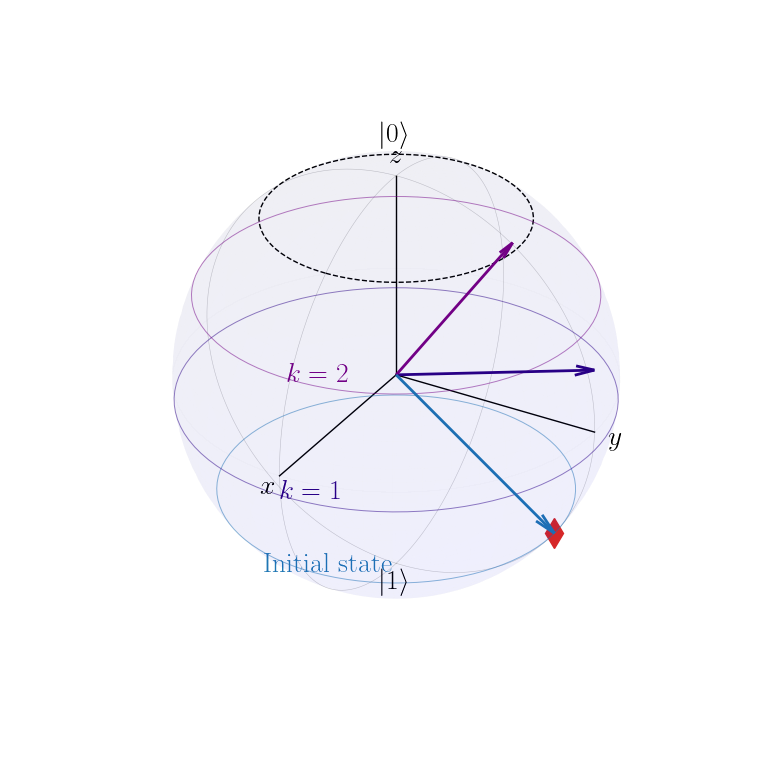

In [163]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')

# Plot the Bloch sphere with vector
i=0
for state in states_bad:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='d',marker_color='C3')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_bad.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()
